# 逐层敏感性：activation 空间 vs function（logit）空间

**一句话问题**：如果把每层的步长按"该层 activation 变化多少"来定，和按"该层让最终预测分布偏多少"来定，
结果会一样吗？如果不一样，那就说明 **控制 activation change 不能替代真正的 function-space step size**。

### 两个被测量的量

对每个 Muon 矩阵 `W_l`（每层 7 个：q/k/v/o/gate/up/down），取优化器当前的正交化方向 `D_l`
（动量做 Newton–Schulz，再乘 Muon 的形状因子），定义：

| 记号 | 定义 | 对应哪种步长规则 |
|---|---|---|
| **activation sensitivity** `a_l` | `‖ΔH_l‖_F / ‖H_l‖_F`，其中 `ΔW_l = -D_l` | activation 规则：`α_l ∝ 1/a_l`（这正是 `intent_l` 归一化的量） |
| **function sensitivity** `s_l` | `½·Var_p[∂z/∂η]`，即单位 η 下 logits 变化的**预测分布方差** | logit-KL 规则：`η_l ∝ 1/√s_l`（这正是 `η_l = sqrt(2ε/vᵀFv)` 的分母） |

`s_l` 的等价说法：`KL(p‖p') ≈ ½η²·Var_p[v]`，所以 `s_l` 就是**单位 η² 对应的 KL**。

### 判据

两条规则的步长之比是 `η_l/α_l ∝ a_l/√s_l`。所以：

- 如果 `log s_l − 2 log a_l` 在各层上**几乎不变** → 两种规则给出近似相同的相对步长，
  **逐层 function-space 步长的研究价值有限**，activation 归一化已经够了。
- 如果它**变化很大** → activation 归一化无法替代 function-space 步长，
  这正是 Layer-wise Logit-KL Intentional Muon 的立论基础。

本 notebook 直接把这个量画出来。

> **数值提醒**：在接近均匀的 `p` 下，单位 η 引起的 KL 约为 1e-13，低于 fp32 分辨率。
> 所以探测全部在 **float64** 下做，`v_l` 用 logits 的有限差分估计，而不是相减两个几乎相等的 KL。
> 每次都会打印两项自检：线性性（`linearity_ratio≈1`）和二次 KL 模型（`kl_pred_over_meas≈1`）。

## 0. 运行说明

| 事项 | 说明 |
|---|---|
| 依赖 | 公共 `llmenv`，代码在 `~/muon_intentional/src/muonint/` |
| GPU 时长 | **约 4–6 分钟（1 张 H100）**：训 80M token 的小模型 ≈2 分钟，其余是探测 |
| 并发 | 1，串行 |
| `MODE` | `"quick"` 是 CPU 也能跑的管道检查（~10 秒）；正式结果用 `"full"` |
| 探测成本 | 每个检查点 42 层 × 2 个 η × 一次 float64 前向（2 条序列），总共几秒 |

In [1]:
import os, sys, math, time
import numpy as np
import torch

ROOT = "/home/15Cu2Plus/muon_intentional"
sys.path.insert(0, os.path.join(ROOT, "src"))

from muonint.pretrain import RunConfig
from muonint.sensitivity import train_with_probes, summarize, compare_views, fmt_tokens

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)

MODE = "full"          # "quick" 先把管道跑通
DATA = os.path.join(ROOT, "data", "climbmix_400m.u16")

P = dict(d=384, L=6, H=6, seq=512, batch=32, tokens=80_000_000, lr=0.02,
         etas=(1e-2, 3e-3), probe_seqs=2, ckpt_fracs=(0.02, 0.5, 1.0))
if MODE == "quick":
    P.update(d=128, L=2, H=2, seq=128, batch=8, tokens=40_000, probe_seqs=2,
             ckpt_fracs=(0.5, 1.0))

RES = os.path.join(ROOT, "results", "sensitivity", MODE)
os.makedirs(RES, exist_ok=True)
print("MODE =", MODE)

device: cuda | torch 2.14.0+cu130
MODE = full


In [2]:
from muonint.data import build_token_cache
t0 = time.time()
build_token_cache(DATA, 400_000_000)
print(f"{os.path.getsize(DATA)/1e9:.2f} GB, {time.time()-t0:.0f}s")

[cache] /home/15Cu2Plus/muon_intentional/data/climbmix_400m.u16 exists (800 MB), reusing
0.80 GB, 0s


## 1. 训练并用 Muon 的方向做探测

用经典固定步长 Muon 训一个小 GPT，在 3 个检查点（2% / 50% / 100% 训练量）测量两种敏感性。
探测用的是**优化器当前的动量方向**，也就是它实际在走的方向，而不是临时算的梯度。

主图用最后一个检查点；三个检查点的统计量都会打印出来，用来看结论是否稳定。

In [3]:
cfg = RunConfig(name="sens", opt_mode="fixed", lr=P["lr"], adam_lr=3e-4,
                n_layer=P["L"], n_head=P["H"], d_model=P["d"], seq_len=P["seq"],
                batch_size=P["batch"], tokens=P["tokens"], seed=0,
                log_every=10**9, eval_every=10**9,
                data_path=DATA, out_dir=RES)

t0 = time.time()
model, res = train_with_probes(cfg, ckpt_fracs=P["ckpt_fracs"], probe_seqs=P["probe_seqs"],
                               etas=P["etas"], device=DEVICE)
ckpts = sorted(k for k in res if isinstance(k, int))
print(f"\n训练 + 探测用时 {(time.time()-t0)/60:.1f} min")
print("检查点（step → tokens）:", {k: fmt_tokens(res['tokens'][k]) for k in ckpts})
FINAL = ckpts[-1]

  probe @ 1.6M tokens, loss 6.316
  probe @ 40.0M tokens, loss 4.060
  probe @ 80.0M tokens, loss 3.888

训练 + 探测用时 4.8 min
检查点（step → tokens）: {98: '1.6M', 2441: '40.0M', 4882: '80.0M'}


In [4]:
import matplotlib as mpl
import matplotlib.pyplot as plt

SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "figure.dpi": 120,
})

def style_axes(ax, title=None, xlabel=None, ylabel=None):
    if title: ax.set_title(title, color=INK, loc="left", pad=10)
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    return ax

def draw_layer_bars(ax, values, labels, color, logy=False):
    """One bar per (block, matrix); light separators between blocks."""
    x = np.arange(len(values))
    ax.bar(x, values, color=color, width=0.72)
    n_blk = sum(1 for l in labels if l.endswith(".q"))
    per = len(labels) // max(1, n_blk)
    for i in range(per, len(labels), per):
        ax.axvline(i - 0.5, color=GRID, lw=1.0, zorder=0)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90, fontsize=6)
    ax.grid(axis="x", visible=False)
    if logy: ax.set_yscale("log")
    return x

# 图内文字一律用英文：集群没有 CJK 字体
print("plot style ready")

plot style ready


## 2. 图 1：逐层 activation sensitivity

**横轴** Transformer layer（每个块 7 个矩阵，顺序 q/k/v/o/gate/up/down）；
**纵轴** 单位 Muon 更新引起的**相对 activation 变化** `‖ΔH_l‖/‖H_l‖`。

这张图回答：不同层之间，activation 空间的敏感性有没有显著差异？

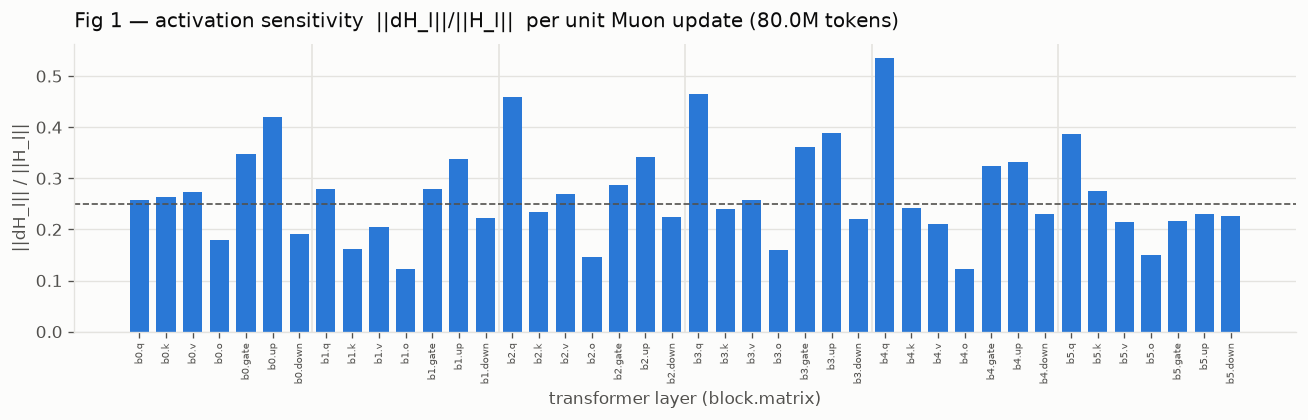

a_l: 中位数 0.250  最大/最小 = 4.37x  log-CV = 0.343


In [5]:
r = res[FINAL]
a_l = r["activation"]
labels = r["labels"]

fig, ax = plt.subplots(figsize=(11, 3.6))
draw_layer_bars(ax, a_l, labels, SLOT[0])
ax.axhline(np.median(a_l), color=INK2, lw=1, ls="--")
style_axes(ax, f"Fig 1 — activation sensitivity  ||dH_l||/||H_l||  per unit Muon update "
               f"({fmt_tokens(res['tokens'][FINAL])} tokens)",
          "transformer layer (block.matrix)", "||dH_l|| / ||H_l||")
plt.tight_layout(); plt.show()

print(f"a_l: 中位数 {np.median(a_l):.3f}  最大/最小 = {a_l.max()/a_l.min():.2f}x  "
      f"log-CV = {np.std(np.log(a_l)):.3f}")

## 3. 图 2：逐层 function sensitivity

**纵轴** 单位 η² 引起的 **logits KL**：`s_l = ½·Var_p[∂z/∂η]`。
这就是 `η_l = sqrt(2ε / vᵀF_z v)` 里那个分母的一半——也就是说，这张图的倒数直接决定
Logit-KL 规则会给每层多大的步长。

注意纵轴是对数刻度：如果 function sensitivity 的层间跨度远大于 activation sensitivity，
那意味着"哪一层更敏感"这件事在两个空间里的答案根本不同。

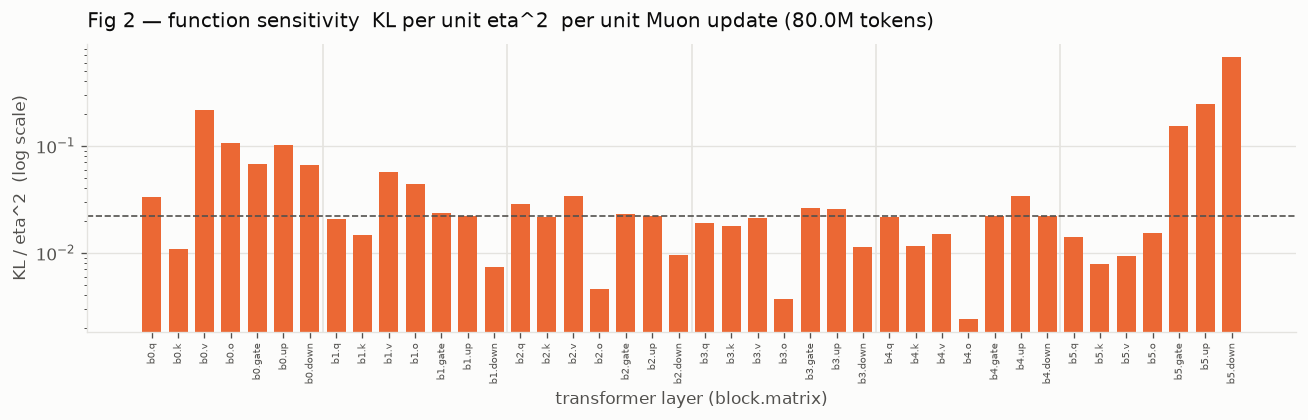

s_l: 中位数 2.200e-02  最大/最小 = 279.0x  log-CV = 1.107
对比 a_l 的跨度: 4.37x


In [6]:
s_l = r["function"][min(P["etas"])]      # 最小 η，最接近线性区

fig, ax = plt.subplots(figsize=(11, 3.6))
draw_layer_bars(ax, s_l, labels, SLOT[1], logy=True)
ax.axhline(np.median(s_l), color=INK2, lw=1, ls="--")
style_axes(ax, f"Fig 2 — function sensitivity  KL per unit eta^2  per unit Muon update "
               f"({fmt_tokens(res['tokens'][FINAL])} tokens)",
          "transformer layer (block.matrix)", "KL / eta^2  (log scale)")
plt.tight_layout(); plt.show()

print(f"s_l: 中位数 {np.median(s_l):.3e}  最大/最小 = {s_l.max()/s_l.min():.1f}x  "
      f"log-CV = {np.std(np.log(s_l)):.3f}")
print(f"对比 a_l 的跨度: {a_l.max()/a_l.min():.2f}x")

## 4. 图 3：两者一致吗？—— **这才是判据**

把两套数字放到同一个坐标系里。左边是每层的 `(a_l, s_l)`（各自除以自己的几何平均，
所以 1 表示"典型层"）；右边是**两种规则给出的步长之比** `η_l/α_l ∝ a_l/√s_l`
（同样归一化），它直接告诉我们"如果改用 function-space 定步长，每层的步长会怎么变"。

- 点都落在对角线上、右图的柱子都在 1 附近 → 两种视角等价，逐层 intentional 没有额外价值。
- 点散开、右图柱子跨很多倍 → activation 归一化无法替代 function-space 步长。

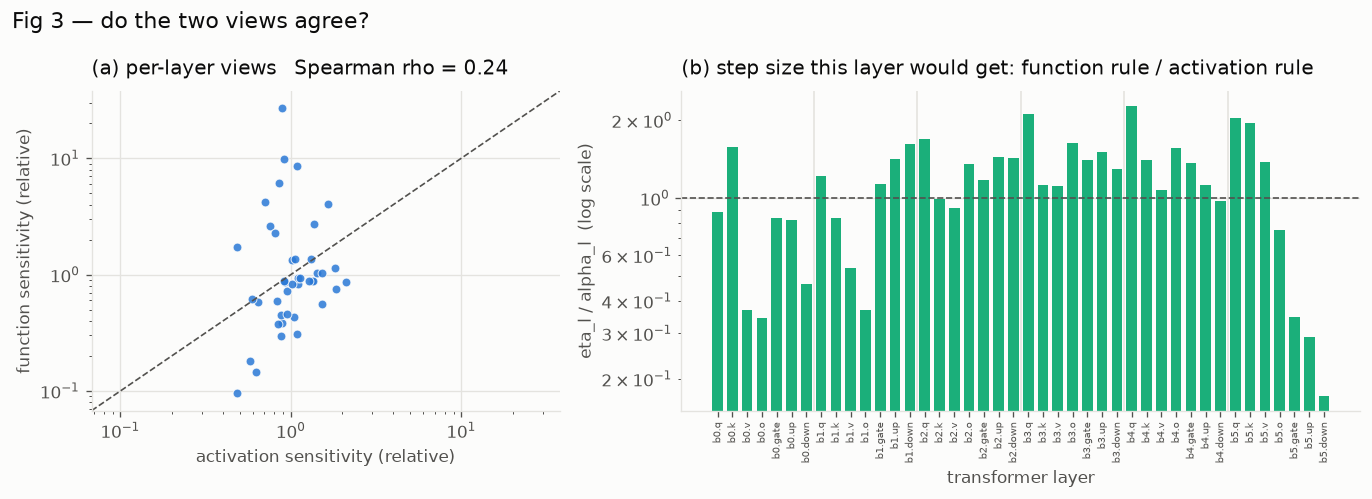

两种规则的步长之比：中位数 1.00，p90/p10 = 4.6x，log-CV = 0.59


In [7]:
la = np.log(a_l); ls = np.log(s_l)
a_n = np.exp(la - la.mean())            # 相对典型层
s_n = np.exp(ls - ls.mean())
gap = ls - 2 * la                       # log(s/a^2)
step_ratio = np.exp(-gap / 2)           # eta_l / alpha_l, normalised
step_ratio /= np.exp(np.log(step_ratio).mean())

rho = compare_views(a_l, s_l)["spearman"]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2),
                         gridspec_kw={"width_ratios": [1, 1.45]})

ax = axes[0]
ax.scatter(a_n, s_n, s=28, color=SLOT[0], alpha=0.85, edgecolor=SURF, linewidth=0.6)
lim = [min(a_n.min(), s_n.min()) * 0.7, max(a_n.max(), s_n.max()) * 1.4]
ax.plot(lim, lim, color=INK2, lw=1, ls="--")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lim); ax.set_ylim(lim)
style_axes(ax, f"(a) per-layer views   Spearman rho = {rho:.2f}",
           "activation sensitivity (relative)", "function sensitivity (relative)")

ax = axes[1]
x = np.arange(len(labels))
ax.bar(x, step_ratio, color=SLOT[2], width=0.72)
ax.axhline(1.0, color=INK2, lw=1, ls="--")
for i in range(7, len(labels), 7):
    ax.axvline(i - 0.5, color=GRID, lw=1.0, zorder=0)
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=90, fontsize=6)
ax.set_yscale("log"); ax.grid(axis="x", visible=False)
style_axes(ax, "(b) step size this layer would get: function rule / activation rule",
           "transformer layer", "eta_l / alpha_l  (log scale)")

fig.suptitle("Fig 3 — do the two views agree?", x=0.01, ha="left", color=INK, fontsize=13)
plt.tight_layout(); plt.show()

spread = np.exp(np.percentile(np.log(step_ratio), 90) - np.percentile(np.log(step_ratio), 10))
print(f"两种规则的步长之比：中位数 1.00，p90/p10 = {spread:.1f}x，"
      f"log-CV = {np.std(np.log(step_ratio)):.2f}")

## 5. 统计量（三个检查点都要稳）

`log s_l − 2 log a_l` 的离散度（`cv_step_ratio`）是核心数字：它等于两种规则步长之比的 log-CV。

自检项：`linearity_ratio` 应 ≈1（说明还在线性区），`kl_pred_over_meas` 应 ≈1
（说明二次 KL 模型成立）。这两个不接近 1 说明探测本身不可信，此时不要解读主结论。

In [8]:
rows = []
for k in ckpts:
    st = summarize(res[k])
    rows.append((k, st))

hdr = f"{'step':>6} {'tokens':>8} {'Spearman':>9} {'logCV(a)':>9} {'logCV(s)':>9} " \
      f"{'logCV(step)':>12} {'lin':>6} {'KLchk':>7}"
print(hdr); print("-" * len(hdr))
for k, st in rows:
    print(f"{k:>6} {fmt_tokens(res['tokens'][k]):>8} {st['spearman']:>9.3f} "
          f"{st['cv_activation']:>9.3f} {st['cv_function']:>9.3f} "
          f"{st['cv_step_ratio']:>12.3f} {st['linearity_ratio']:>6.3f} "
          f"{st['kl_pred_over_meas']:>7.3f}")

print("\n逐层明细（最后一个检查点）：")
print(f"{'layer':>10} {'a_l':>10} {'s_l':>12} {'eta/alpha':>10}")
for i, lab in enumerate(labels):
    print(f"{lab:>10} {a_l[i]:>10.3f} {s_l[i]:>12.3e} {step_ratio[i]:>10.2f}")

  step   tokens  Spearman  logCV(a)  logCV(s)  logCV(step)    lin   KLchk
-------------------------------------------------------------------------
    98     1.6M     0.283     0.152     1.277        1.138  0.999   1.000
  2441    40.0M     0.346     0.327     0.976        0.922  1.000   1.000
  4882    80.0M     0.235     0.343     1.107        1.183  1.000   1.000

逐层明细（最后一个检查点）：
     layer        a_l          s_l  eta/alpha
      b0.q      0.258    3.338e-02       0.88
      b0.k      0.264    1.095e-02       1.58
      b0.v      0.274    2.154e-01       0.37
      b0.o      0.179    1.061e-01       0.34
   b0.gate      0.348    6.781e-02       0.83
     b0.up      0.420    1.017e-01       0.82
   b0.down      0.191    6.552e-02       0.47
      b1.q      0.279    2.066e-02       1.21
      b1.k      0.162    1.459e-02       0.84
      b1.v      0.205    5.677e-02       0.54
      b1.o      0.123    4.354e-02       0.37
   b1.gate      0.279    2.364e-02       1.13
     b1.up      

## 6. 判读

对照事先写好的标准（不看完结果再补）：

| 观察 | 结论 |
|---|---|
| `cv_step_ratio` < 0.2 且 Spearman > 0.8 | 两种视角基本等价 → 逐层 function-space 步长的价值存疑，**这个方向要重新考虑** |
| `cv_step_ratio` 在 0.2–0.7，Spearman 中等 | 有差异但不悬殊 → 逐层 intentional 是一个"小而真实"的改进，不足以撑起独立课题，但可以作为完整工作的一个组件 |
| `cv_step_ratio` > 0.7 或 Spearman < 0.5 | 两种视角显著不同 → **activation 归一化无法替代 function-space 步长**，Logit-KL 逐层步长有实质内容 |

第三个检查点若与第二个差异很大，说明结论对训练阶段敏感，需要报告整条曲线而不是单点。

In [9]:
st = summarize(res[FINAL])
cv, rho = st["cv_step_ratio"], st["spearman"]
print("=" * 70)
print(f"最终检查点：Spearman={rho:.2f}  log-CV(step ratio)={cv:.2f}  "
      f"步长比 p90/p10={spread:.1f}x")
print(f"自检：linearity={st['linearity_ratio']:.3f} (应≈1)  "
      f"KL model={st['kl_pred_over_meas']:.3f} (应≈1)")
print("-" * 70)

if not (0.9 < st["linearity_ratio"] < 1.1 and 0.9 < st["kl_pred_over_meas"] < 1.1):
    print("⚠ 自检没通过，主结论不可信，先查探测实现。")
elif cv < 0.2 and rho > 0.8:
    print("→ 两种视角基本等价。逐层 function-space 步长相对 activation 归一化没有多少增量，")
    print("  这个方向的吸引力下降；若要继续，需要把 novelty 放在别处（如跨时间自适应）。")
elif cv <= 0.7:
    print("→ 有差异但不悬殊。逐层 intentional 是一个真实但偏小的改进；")
    print("  建议把它当作更完整工作的一部分，而不是课题主体。")
else:
    print("→ 两种视角显著不同：activation 归一化**无法**替代 function-space 步长。")
    print("  这支持 Layer-wise Logit-KL Intentional Muon 的立论。")
    print("  注意：这只说明“目标不同”，还没说明“新的目标更好”——后者要另外比较 val loss。")
print("=" * 70)

cv_all = [summarize(res[k])["cv_step_ratio"] for k in ckpts]
print(f"\n跨检查点稳定性：log-CV(step ratio) = " +
      ", ".join(f"{c:.2f}" for c in cv_all) +
      ("  ← 稳定" if max(cv_all) - min(cv_all) < 0.3 else "  ← 随训练变化明显，需报告曲线"))

最终检查点：Spearman=0.24  log-CV(step ratio)=1.18  步长比 p90/p10=4.6x
自检：linearity=1.000 (应≈1)  KL model=1.000 (应≈1)
----------------------------------------------------------------------
→ 两种视角显著不同：activation 归一化**无法**替代 function-space 步长。
  这支持 Layer-wise Logit-KL Intentional Muon 的立论。
  注意：这只说明“目标不同”，还没说明“新的目标更好”——后者要另外比较 val loss。

跨检查点稳定性：log-CV(step ratio) = 1.14, 0.92, 1.18  ← 稳定


---

### 这张图能证明什么、不能证明什么

**能证明**：两种步长规则在层间的分配是否不同。这是"逐层 function-space 步长有没有独立性"的**必要条件**。

**不能证明**：新的目标更好。两种规则给出不同分配，也可能只是 function 视角更差。
那要靠在相同 token 预算下比较 val loss 才能回答（这是另一个 notebook 的事）。

**另一个注意点**：这里测的是"单位方向"的敏感性，也就是局部的、一阶的量。
真实训练里 η 会被这个量归一化到同一个 KL 目标上，所以这张图恰好刻画了那个归一化会带来多大的层间差异。
如果训练早期的 `p` 接近均匀（KL 敏感度极低），`η_l` 可能全部撞到上限，此时这张图的差异就被抹平了——
所以第一个检查点的数字（2% 训练量）值得特别看一眼。